## Figure 3. The NMWI outperforms conventional diversity metrics in distinguishing health from disease. 
**(a)** NMWI and diversity metrics (Shannon, Simpson, Chao1) compared between healthy and non-healthy samples (two-sided Mann–Whitney U tests; |Cliff's δ|). Distributions of NMWI scores **(b)** and Shannon diversity (c) across healthy samples and individual disease cohorts (two-sided Mann–Whitney U tests; |Cliff's δ|). Significance is denoted by * (P < 0.01) and n.s. (not significant).


In [2]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import glob, warnings, sys, runpy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut, GridSearchCV, RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import balanced_accuracy_score, recall_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import joblib
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", message="pkg_resources is deprecated as an API")


In [3]:
# Run only once to get the working directory
project_root = Path("../../").resolve()
os.chdir(project_root)
print("Working dir:", Path.cwd())

In [4]:
%matplotlib inline
# METADATA LOADING
vars_dict = runpy.run_path("Codes/Auxiliary_files/Generate_data_index.py")
globals().update(vars_dict)
X_new = X.copy()

Found 27 genus tables in index
Number of samples: 1654, and number of taxa: 184
Number of unique studies: 27

Sample ID per Category:
Category  n_Sample ID
    case         1065
 control          589


- X: DataFrame (rows=samples, cols=taxonomy), index includes bioproject/sample_id RELATIVE ABUNDANCE
- y: Series/array-like of True/False (same index as X), True (1) =control, False=case

In [4]:
%run -i Codes/Auxiliary_files/NMWI.py # Run model

# Read alpha diversity file:
alpha_df = pd.read_csv("Data/AlphaDiversity_metrics.csv").set_index('Sample ID')

Positive coefs: 14
Negative coefs: 10
zero coefs: 160
Resubstitution estimate: 0.744
LOSO accuracy: 0.7301


### Figure 3.a
NMWI and diversity metrics (Shannon, Simpson, Chao1) compared between healthy and non-healthy samples (two-sided Mann–Whitney U tests; |Cliff's δ|). 

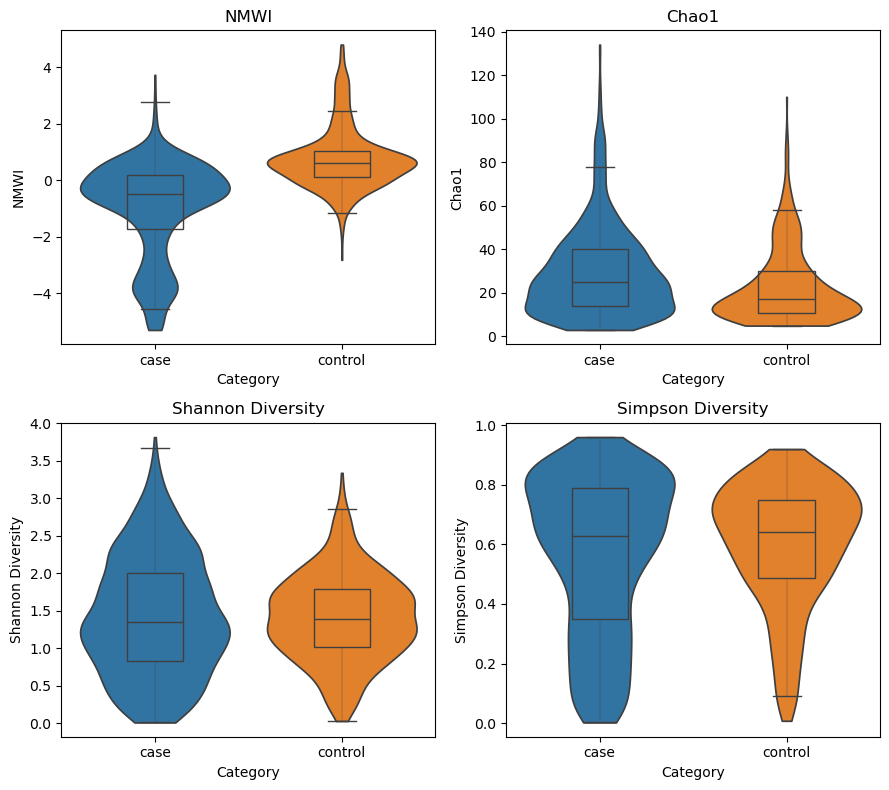

In [5]:
# Violin plots
plot_vars = ["NMWI", "Chao1", "Shannon Diversity", "Simpson Diversity"]
plot_df = alpha_df.reset_index().copy()
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
axes = axes.flatten()

for ax, var in zip(axes, plot_vars):
    sns.violinplot(data=plot_df, x="Category", y=var, hue="Category",
                   inner=None, ax=ax, cut=0)
    sns.boxplot(data=plot_df, x="Category", y=var, width=0.3,
                showcaps=True, boxprops={"facecolor": "none", "zorder": 3},
                showfliers=False, whiskerprops={"linewidth": 0.25}, ax=ax)
    ax.set_title(var)

plt.tight_layout()
plt.show()

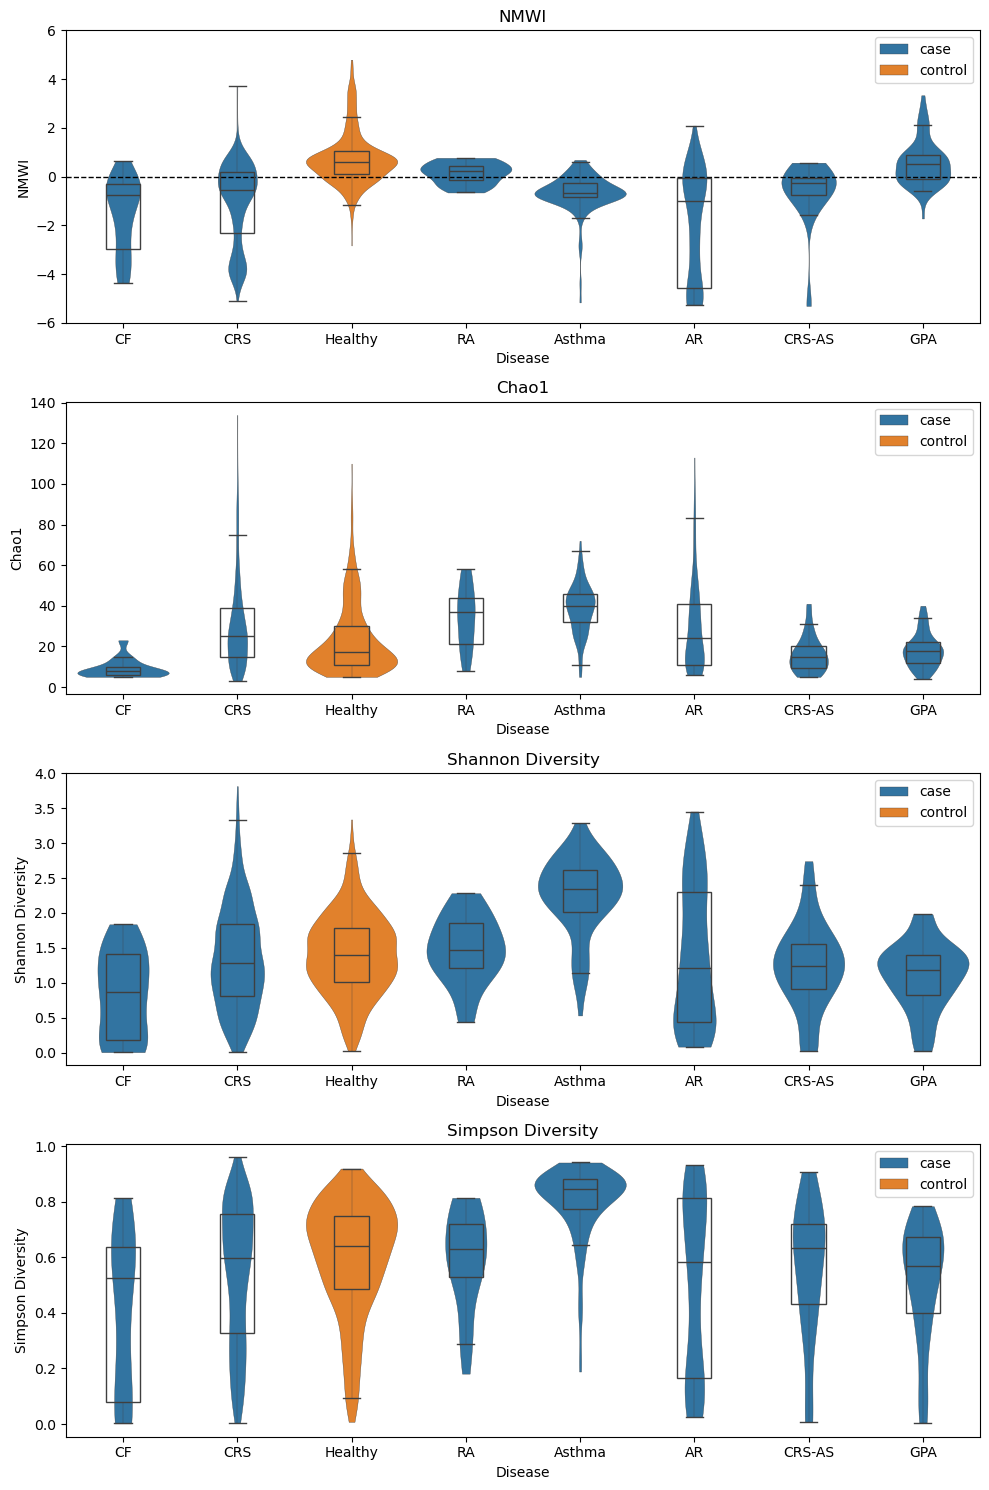

In [6]:
from scipy.stats import mannwhitneyu

def group_test(a, b):
    a, b = a.dropna(), b.dropna()
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    delta = 2 * u / (len(a) * len(b)) - 1
    return delta, p

alpha_metrics = ["NMWI", "Chao1", "Shannon Diversity", "Simpson Diversity"]

# Category comparison
cat1, cat2 = plot_df["Category"].dropna().unique()[:2]
results = []

for metric in alpha_metrics:
    a = plot_df.loc[plot_df["Category"] == cat1, metric]
    b = plot_df.loc[plot_df["Category"] == cat2, metric]
    delta, p = group_test(a, b)
    results.append([metric, cat1, cat2, a.notna().sum(), b.notna().sum(), delta, p])

category_stats = pd.DataFrame(
    results,
    columns=["Metric", "Category_1", "Category_2", "N_1", "N_2",
             "Cliffs_delta", "MannWhitney_p"]
)

# Disease vs Healthy
results = []
diseases = plot_df.loc[plot_df["Disease"].ne("Healthy"), "Disease"].dropna().unique()

for metric in alpha_metrics:
    healthy = plot_df.loc[plot_df["Disease"] == "Healthy", metric]
    for disease in diseases:
        case = plot_df.loc[plot_df["Disease"] == disease, metric]
        delta, p = group_test(case, healthy)
        results.append([metric, disease, "Healthy",
                        case.notna().sum(), healthy.notna().sum(), delta, p])

stats_df = pd.DataFrame(
    results,
    columns=["Metric", "Group_1", "Group_2", "N_1", "N_2",
             "Cliffs_delta", "MannWhitney_p"]
)

# Disease-level violin plots
fig, axes = plt.subplots(len(alpha_metrics), 1, figsize=(10, 15))

for ax, var in zip(axes, alpha_metrics):
    sns.violinplot(data=plot_df, x="Disease", y=var, hue="Category",
                   inner=None, linewidth=0.25, cut=0, ax=ax)
    sns.boxplot(data=plot_df, x="Disease", y=var, width=0.3,
                showcaps=True, showfliers=False,
                boxprops={"facecolor": "none", "zorder": 3},
                whiskerprops={"linewidth": 0.25}, ax=ax)
    ax.set_title(var)

axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_ylim(-6, 6)
plt.tight_layout()
plt.show()

In [7]:
print(category_stats)

              Metric Category_1 Category_2   N_1  N_2  Cliffs_delta  \
0               NMWI       case    control  1065  589     -0.653650   
1              Chao1       case    control  1065  589      0.200400   
2  Shannon Diversity       case    control  1065  589     -0.009659   
3  Simpson Diversity       case    control  1065  589     -0.030383   

   MannWhitney_p  
0  1.156033e-107  
1   1.385791e-11  
2   7.446850e-01  
3   3.056053e-01  


In [8]:
print(stats_df)

               Metric Group_1  Group_2  N_1  N_2  Cliffs_delta  MannWhitney_p
0                NMWI      CF  Healthy   30  589     -0.873005   6.925569e-16
1                NMWI     CRS  Healthy  652  589     -0.662348   1.698605e-90
2                NMWI      RA  Healthy   21  589     -0.392352   2.235744e-03
3                NMWI  Asthma  Healthy  123  589     -0.804436   8.310141e-45
4                NMWI      AR  Healthy  137  589     -0.723817   7.902377e-40
5                NMWI  CRS-AS  Healthy   34  589     -0.697393   7.784551e-12
6                NMWI     GPA  Healthy   68  589     -0.118196   1.102926e-01
7               Chao1      CF  Healthy   30  589     -0.672100   5.052032e-10
8               Chao1     CRS  Healthy  652  589      0.219002   2.523802e-11
9               Chao1      RA  Healthy   21  589      0.438354   6.329012e-04
10              Chao1  Asthma  Healthy  123  589      0.581045   3.388561e-24
11              Chao1      AR  Healthy  137  589      0.163806  